# Valutare un investimento immobiliare: esempio guidato

Un cliente valuta l'acquisto di un **bilocale a Milano da 280.000 €**, da ristrutturare e affittare, con un mutuo al 60%. Chiede un rendimento minimo del **5% annuo** sul capitale che mette di tasca propria.

In questo notebook rispondiamo a tre domande:
1. Quanto rende davvero, dopo spese, imposte e rata?
2. Quali ipotesi contano di più?
3. Qual è il prezzo massimo da offrire per ottenere il rendimento richiesto?

In [1]:
import pandas as pd
import plotly.io as pio

from real_estate_analyzer import calcola, costo_iniziale, esempio_milano, proiezione
from real_estate_analyzer import sensitivita as sens
from real_estate_analyzer.report import analizza, grafico_cascata, grafico_griglia, grafico_tornado

pio.renderers.default = "png"  # immagini statiche, visibili anche su GitHub
pd.options.display.float_format = "{:,.0f}".format

## 1. Ipotesi ed esborso iniziale

Le ipotesi sono raccolte in un oggetto `Investimento`; si possono leggere anche da un file TOML (vedi `examples/trilocale_torino.toml`).

In [2]:
inv = esempio_milano()
inv

Investimento(acquisto=Acquisto(prezzo=280000, rendita_catastale=950, prima_casa=False, da_impresa=False, aliquota_iva=0.1, agenzia=0.03, notaio=2800, ristrutturazione=20000, arredo=8000, valore_mercato=315000), locazione=Locazione(canone_mensile=1300, crescita_canone=0.02, sfitto=0.04, canone_concordato=False, regime='cedolare', aliquota_irpef=0.35, addizionali=0.02), spese=Spese(condominio=700, manutenzione=900, assicurazione=250, gestione=0.0, aliquota_imu=0.0106, inflazione=0.02), mutuo=Mutuo(ltv=0.6, tasso=0.03, durata_anni=25, spese_istruttoria=1000.0, perizia=300.0), scenario=Scenario(orizzonte=10, crescita_valore=0.02, costi_vendita=0.03, tasso_sconto=0.05), nome='Bilocale Milano, zona Città Studi')

In [3]:
costo = costo_iniziale(inv)
voci = costo.voci()
voci[voci > 0].to_frame("€")

,€
Prezzo,"280,000"
Imposta di registro,"10,773"
Imposte ipotecaria e catastale,100
Agenzia (IVA inclusa),"10,248"
Notaio,"2,800"
Ristrutturazione,"20,000"
Arredo,"8,000"
Oneri del mutuo,"4,660"


In [4]:
print(f"Costo complessivo  € {costo.totale:,.0f}")
print(f"Mutuo              € {costo.importo_mutuo:,.0f}")
print(f"Capitale proprio   € {costo.capitale_proprio:,.0f}")

Costo complessivo  € 336,581
Mutuo              € 168,000
Capitale proprio   € 168,581


Oltre al prezzo servono circa **28.000 € di imposte, agenzia, notaio e oneri del mutuo**: l'imposta di registro si paga sul valore catastale (rendita × 1,05 × 120 × 9%), non sul prezzo.

## 2. Flussi di cassa

Proiezione annua fino alla vendita dopo 10 anni.

In [5]:
df = proiezione(inv)
df[["Canone incassato", "IMU", "NOI", "Imposte sul reddito", "Interessi", "Quota capitale",
    "Vendita netta", "Flusso netto"]].T

Anno,0,1,2,3,4,5,6,7,8,9,10
Canone incassato,0,"14,976","15,276","15,581","15,893","16,211","16,535","16,865","17,203","17,547","17,898"
IMU,0,"1,692","1,692","1,692","1,692","1,692","1,692","1,692","1,692","1,692","1,692"
NOI,0,"11,434","11,697","11,965","12,238","12,516","12,800","13,090","13,386","13,687","13,995"
Imposte sul reddito,0,"3,145","3,208","3,272","3,337","3,404","3,472","3,542","3,613","3,685","3,759"
Interessi,0,"4,977","4,838","4,694","4,546","4,394","4,237","4,075","3,908","3,736","3,559"
Quota capitale,0,"4,583","4,722","4,866","5,014","5,166","5,323","5,485","5,652","5,824","6,001"
Vendita netta,0,0,0,0,0,0,0,0,0,0,"372,464"
Flusso netto,"-168,581","-1,271","-1,071",-868,-660,-448,-232,-12,213,443,"257,777"


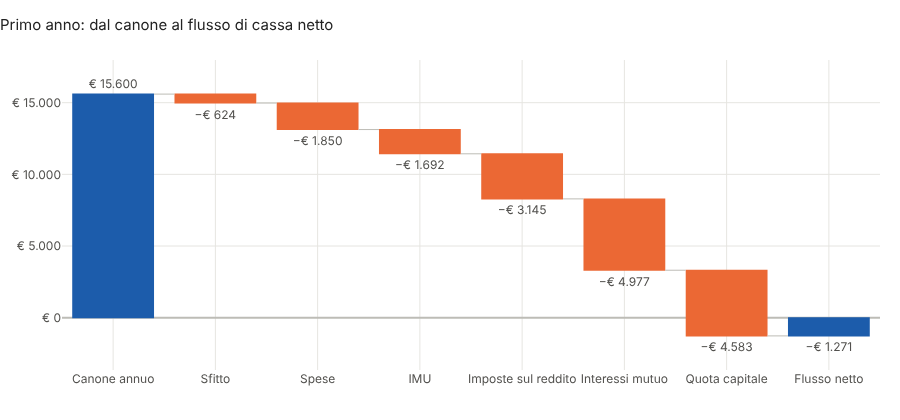

In [6]:
a = analizza(inv, n_simulazioni=500)
grafico_cascata(a).show(width=900)

Nel primo anno il canone non basta a coprire spese, imposte e rata: il cliente deve **integrare circa 100 € al mese**. Il guadagno arriva soprattutto dalla vendita finale.

## 3. Indicatori

In [7]:
ind = calcola(inv)
pd.Series(ind).to_frame("Valore").style.format("{:,.3f}")

,Valore
Costo complessivo,"336,581.000"
Capitale proprio,"168,581.000"
Importo mutuo,"168,000.000"
Rendimento lordo,0.056
Rendimento netto,0.025
Cap rate,0.036
Cash-on-cash,-0.008
DSCR minimo,1.196
VAN,"-13,905.247"
TIR,0.041


Il TIR del capitale proprio è intorno al **4,1%**, sotto il 5% richiesto: il VAN è negativo. Il cap rate (3,6%) supera di poco il tasso del mutuo (3,0%): per questo la leva migliora il rendimento solo di poco (TIR senza leva 3,8%).

## 4. Sensitività

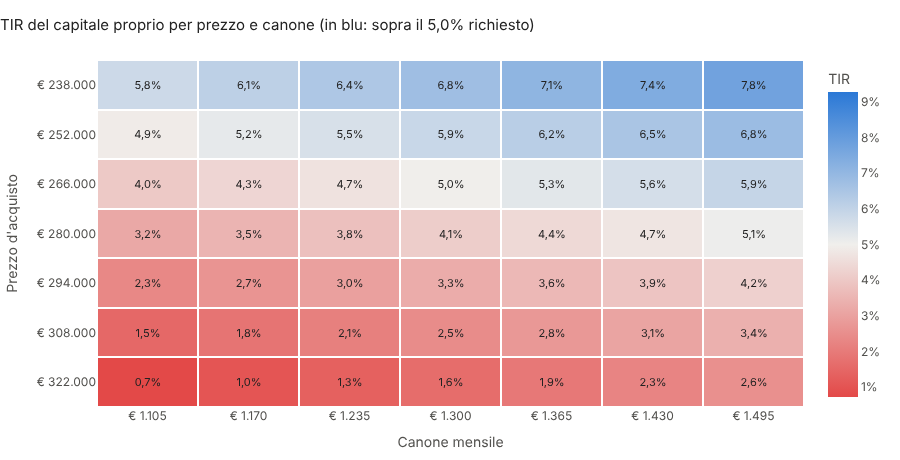

In [8]:
grafico_griglia(a).show(width=900)

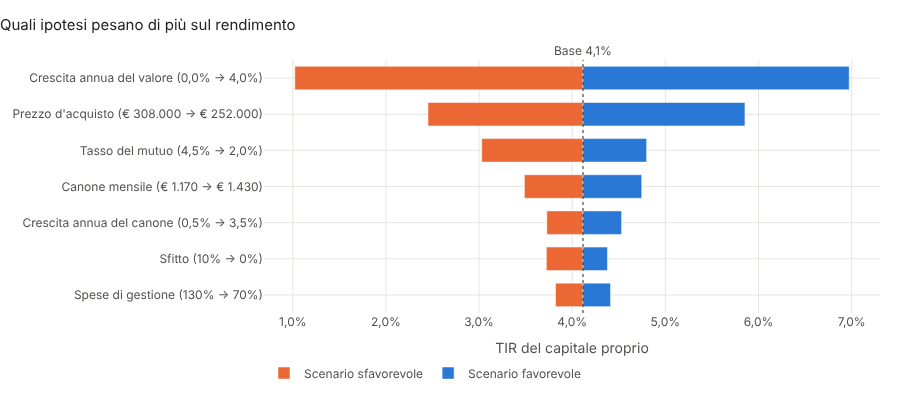

In [9]:
grafico_tornado(a).show(width=900)

La **crescita del valore** dell'immobile e il **prezzo d'acquisto** pesano molto più di canone e sfitto: la trattativa sul prezzo è la leva più concreta a disposizione del cliente.

## 5. Scenari e prezzo massimo

In [10]:
sens.confronta_scenari(sens.scenari_standard(inv)).style.format(
    {"Capitale proprio": "€ {:,.0f}", "VAN": "€ {:,.0f}", "Rendimento netto": "{:.2%}",
     "Cash-on-cash": "{:.2%}", "TIR": "{:.2%}", "Moltiplicatore del capitale": "{:.2f}×"})

,Capitale proprio,Rendimento netto,Cash-on-cash,VAN,TIR,Moltiplicatore del capitale
Ipotesi base,"€ 168,581",2.50%,-0.75%,"€ -13,905",4.12%,1.51×
Senza mutuo,"€ 331,921",2.50%,2.50%,"€ -32,602",3.79%,1.40×
Regime IRPEF ordinario,"€ 168,581",1.81%,-2.10%,"€ -32,937",2.91%,1.36×
Canone concordato (−15%),"€ 168,581",2.51%,-0.73%,"€ -13,780",4.12%,1.51×
"Stress: sfitto 10%, valore fermo","€ 168,581",2.27%,-1.19%,"€ -61,187",0.57%,1.06×


In [11]:
print(f"Prezzo massimo d'offerta per un rendimento del 5%: € {ind['Prezzo massimo']:,.0f}")
sim = a.simulazione
print(f"Probabilità di superare il 5% (Monte Carlo): {(sim >= 0.05).mean():.0%}")

Prezzo massimo d'offerta per un rendimento del 5%: € 265,593
Probabilità di superare il 5% (Monte Carlo): 35%


**Conclusione per il cliente:** alle condizioni attuali l'immobile non raggiunge l'obiettivo. Conviene trattare un prezzo intorno a 265.000 € oppure valutare il regime e la struttura del mutuo; il canone concordato, nonostante il canone più basso, rende quanto quello libero grazie alla cedolare al 10% e alla riduzione IMU.

Il report completo per il cliente si genera con:

```bash
real-estate-analyzer --demo --cliente "Mario Rossi"
```